# Notebook 09 — What Aggregation Hides

I ask how much variation in 2024 LSOA fuel-poverty percentages lies within MSOAs and how much lies between their means. I also flag an MSOA when its internal LSOA range exceeds the range of the means for that MSOA and its Notebook 04 neighbours. These are descriptive area-level summaries, not household- or person-level results.


## Setting up

I use the 2024 LSOA fuel-poverty file, the saved LSOA-to-MSOA lookup, Notebook 04's neighbour pairs and the 2021 MSOA boundaries. I reuse the existing Aggregation output folder and overwrite only this notebook's named result files; I check each saved file by reading it back.


In [1]:
# Load the tools for project paths, tables, calculations and figures.
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display

%matplotlib inline

# Find the project from the current folder; accept both saved data-folder layouts.
project_folder = next(p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "Data/Cleaned/Wide/msoa_wide_660.csv").is_file()
    or (p / "data/cleaned/Wide/msoa_wide_660.csv").is_file())
data_folder = project_folder / ("Data" if (project_folder / "Data").is_dir() else "data")

def project_data(relative_path):
    parts = Path(relative_path).parts
    if data_folder.name == "data":
        parts = (parts[0].lower(), *parts[1:])
    return data_folder.joinpath(*parts)

# If the dedicated Unit 3 environment exists, check that this kernel is using it.
expected_environment = project_folder.parent / ".venv-unit3"
if expected_environment.is_dir():
    assert Path(sys.prefix).resolve() == expected_environment.resolve(), "Select the Unit 3 environment."

# Locate the saved boundary file inside the project's raw-data folder.
def raw_file(filename):
    candidates = sorted(project_data("Raw").rglob(filename))
    if not candidates:
        raise FileNotFoundError(f"Raw source not found in the project's raw folder: {filename}")
    return candidates[0]

def read_csv(relative):
    return pd.read_csv(project_data(relative))

# Restrict saved results to this notebook's named folder and expected files.
output_folder = project_data("Cleaned/Aggregation")
figure_folder = output_folder / "figures"
assert output_folder.is_dir() and not output_folder.is_symlink(), "The existing output folder must be a regular directory."
assert figure_folder.is_dir() and not figure_folder.is_symlink(), "The existing figure folder must be a regular directory."
expected_root_outputs = {
    "msoa_fuel_poverty_aggregation.csv", "results_summary.json", "data_dictionary.csv", "figures"
}
expected_figure_outputs = {"09_mixed_areas_map.png", "09_internal_ranges_histogram.png"}
assert {path.name for path in output_folder.iterdir()} == expected_root_outputs
assert {path.name for path in figure_folder.iterdir()} == expected_figure_outputs
assert not any(path.is_symlink() for path in output_folder.iterdir())
assert not any(path.is_symlink() for path in figure_folder.iterdir())

# Check each destination before writing; refuse unexpected names and symbolic links.
def checked_output_path(folder, filename, allowed_names):
    assert filename in allowed_names, f"Unexpected output file name: {filename}"
    path = folder / filename
    assert not path.is_symlink(), f"Refusing to write through a symlink: {path}"
    if path.exists():
        assert path.is_file(), f"Expected a regular file: {path}"
    return path

# Read each saved CSV back and check that its values survived the write.
def save_csv(table, filename, index=False):
    path = checked_output_path(output_folder, filename, expected_root_outputs - {"figures"})
    with path.open("w", encoding="utf-8", newline="") as stream:
        table.to_csv(stream, index=index)
    check = pd.read_csv(path)
    expected = table.reset_index() if index else table.reset_index(drop=True)
    pd.testing.assert_frame_equal(check, expected, check_dtype=False)

# Reject non-finite JSON values and check the saved content by reading it back.
def save_json(value, filename):
    path = checked_output_path(output_folder, filename, expected_root_outputs - {"figures"})
    with path.open("w", encoding="utf-8") as stream:
        json.dump(value, stream, indent=2, ensure_ascii=False, allow_nan=False)
    assert json.loads(path.read_text(encoding="utf-8")) == value

# Save the figure, check that a non-empty file exists, then display and close it.
def save_figure(figure, filename):
    path = checked_output_path(figure_folder, filename, expected_figure_outputs)
    figure.savefig(path, bbox_inches="tight")
    assert path.is_file() and path.stat().st_size > 0
    plt.show()
    plt.close(figure)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
# Keep the expected geography counts and source year explicit for the checks below.
EXPECTED_LSOAS, EXPECTED_MSOAS = 3205, 660
EXPECTED_NEIGHBOUR_PAIRS = 1885
FUEL_POVERTY_PERIOD = 2024
PAPER, INK, SAGE, ACCENT, RULE = "#e9e9e2", "#20271f", "#89956b", "#36557e", "#ccd2c6"

print(f"Notebook 09 inputs: fuel-poverty period {FUEL_POVERTY_PERIOD}; {EXPECTED_LSOAS:,} LSOAs; {EXPECTED_MSOAS:,} MSOAs.")
print(f"Neighbour pairs: {EXPECTED_NEIGHBOUR_PAIRS:,} from Notebook 04. Output: {output_folder.relative_to(project_folder).as_posix()}.")
print("All fuel-poverty values are percentages; ranges are in percentage points. Each LSOA has equal weight in the variance decomposition.")


Notebook 09 inputs: fuel-poverty period 2024; 3,205 LSOAs; 660 MSOAs.
Neighbour pairs: 1,885 from Notebook 04. Output: data/cleaned/Aggregation.
All fuel-poverty values are percentages; ranges are in percentage points. Each LSOA has equal weight in the variance decomposition.


## Preparing the LSOA data

The fuel-poverty file gives one percentage for each LSOA. I check its coverage, units and match to the saved 2021 geography lookup before grouping. The lookup is authoritative for the LSOA-to-MSOA relationship; I also check the MSOA codes already included in the fuel-poverty file.

In [2]:
# Load the saved LSOA fuel-poverty percentages and the authoritative geography lookup.
fuel_source = "Cleaned/Fuel Poverty/fuel_poverty_2024_lsoa_support.csv"
lookup_source = "Prepared/Geography/ons_lsoa21_to_msoa21_lad22_exploratory_west_midlands.csv"
fuel = read_csv(fuel_source)
lookup = read_csv(lookup_source)

# Check one percentage per LSOA, complete coverage and values on the 0–100 scale.
fuel_column = "Proportion of households fuel poor (%)"
assert len(fuel) == EXPECTED_LSOAS and fuel["LSOA Code"].is_unique
assert len(lookup) == EXPECTED_LSOAS and lookup["LSOA21CD"].is_unique
assert fuel[["LSOA Code", "MSOA21CD", fuel_column]].notna().all().all()
assert lookup[["LSOA21CD", "MSOA21CD", "MSOA21NM"]].notna().all().all()
assert set(fuel["LSOA Code"]) == set(lookup["LSOA21CD"])
assert np.isfinite(fuel[fuel_column].to_numpy(float)).all()
assert fuel[fuel_column].between(0, 100).all()

# Join by LSOA code and confirm that the source MSOA codes agree with the lookup.
lookup_small = lookup[["LSOA21CD", "MSOA21CD", "MSOA21NM"]].copy()
lsoa = fuel.merge(lookup_small, left_on="LSOA Code", right_on="LSOA21CD",
                  how="left", validate="one_to_one", suffixes=("", "_lookup"))
assert lsoa["MSOA21CD_lookup"].equals(lsoa["MSOA21CD"])
assert lsoa["MSOA21NM"].notna().all()
assert len(lsoa) == EXPECTED_LSOAS and lsoa["LSOA Code"].is_unique
assert lsoa[fuel_column].between(0, 100).all()

# Verify that all 3,205 LSOAs still cover the expected 660 MSOAs after the join.
expected_codes = set(lookup["MSOA21CD"])
assert len(expected_codes) == EXPECTED_MSOAS
assert set(lsoa["MSOA21CD"]) == expected_codes
print(f"Prepared {len(lsoa):,} unique LSOAs; {lsoa[fuel_column].isna().sum()} fuel-poverty values are missing.")
print(f"All {len(expected_codes):,} MSOAs are represented, and the source MSOA codes match the lookup.")
print(f"Fuel-poverty proportions span {lsoa[fuel_column].min():.2f} to {lsoa[fuel_column].max():.2f} percent.")

Prepared 3,205 unique LSOAs; 0 fuel-poverty values are missing.
All 660 MSOAs are represented, and the source MSOA codes match the lookup.
Fuel-poverty proportions span 2.52 to 32.89 percent.


## Summarising variation inside each MSOA

I calculate the unweighted mean of the LSOA percentages, plus each MSOA's minimum, maximum, range and coefficient of variation. Each LSOA contributes once, regardless of its household count. For the headline decomposition, I split the total variance of all LSOA percentages into the count-weighted average of within-MSOA variances and the LSOA-count-weighted variance of MSOA means. Those components sum to the total variance. This is variation among LSOA percentages, not household-weighted variation.


In [3]:
# Summarise each MSOA's LSOA percentages; every LSOA contributes once, regardless of household count.
area_summary = (
    lsoa.groupby(["MSOA21CD", "MSOA21NM"], as_index=False, sort=True)[fuel_column]
    .agg(
        lsoa_count="count",
        fuel_poverty_mean_unweighted_pct="mean",
        fuel_poverty_min_pct="min",
        fuel_poverty_max_pct="max",
        # Use ddof=0 because this describes the complete set of contributing LSOAs within each MSOA.
        fuel_poverty_sd_population_pct_points=lambda values: values.std(ddof=0),
    )
    .rename(columns={"MSOA21CD": "msoa_code", "MSOA21NM": "msoa_name"})
)
# Range is maximum minus minimum, measured in percentage points.
area_summary["fuel_poverty_range_percentage_points"] = (
    area_summary["fuel_poverty_max_pct"] - area_summary["fuel_poverty_min_pct"]
)
# Divide standard deviation by the mean to express relative spread as a unitless ratio.
area_summary["coefficient_of_variation"] = (
    area_summary["fuel_poverty_sd_population_pct_points"]
    / area_summary["fuel_poverty_mean_unweighted_pct"]
)
# Check that grouping retains every LSOA and produces one complete summary per MSOA.
assert len(area_summary) == EXPECTED_MSOAS and area_summary["msoa_code"].is_unique
assert area_summary[["lsoa_count", "fuel_poverty_mean_unweighted_pct",
                     "fuel_poverty_min_pct", "fuel_poverty_max_pct",
                     "fuel_poverty_range_percentage_points",
                     "fuel_poverty_sd_population_pct_points",
                     "coefficient_of_variation"]].notna().all().all()
assert area_summary["lsoa_count"].sum() == EXPECTED_LSOAS
assert area_summary["lsoa_count"].between(1, EXPECTED_LSOAS).all()
assert area_summary["fuel_poverty_min_pct"].le(area_summary["fuel_poverty_mean_unweighted_pct"]).all()
assert area_summary["fuel_poverty_mean_unweighted_pct"].le(area_summary["fuel_poverty_max_pct"]).all()
assert area_summary["fuel_poverty_range_percentage_points"].ge(0).all()
assert area_summary["coefficient_of_variation"].ge(0).all()

# Start the decomposition from all LSOA percentages, with equal weight per LSOA.
lsoa_values = lsoa[fuel_column].to_numpy(dtype=float)
assert len(lsoa_values) == EXPECTED_LSOAS and np.isfinite(lsoa_values).all()
overall_lsoa_mean_pct = float(np.mean(lsoa_values))
# Population variance is measured in squared percentage points, using ddof=0.
total_variance_percentage_points_squared = float(np.var(lsoa_values, ddof=0))
lsoa_counts = area_summary["lsoa_count"].to_numpy(dtype=float)
msoa_means_pct = area_summary["fuel_poverty_mean_unweighted_pct"].to_numpy(dtype=float)
# Weight each within-MSOA variance by its LSOA count to preserve equal overall LSOA contributions.
within_variance_percentage_points_squared = float(np.average(
    area_summary["fuel_poverty_sd_population_pct_points"].to_numpy(dtype=float) ** 2,
    weights=lsoa_counts,
))
# Weight squared departures of MSOA means from the overall LSOA mean by the same LSOA counts.
between_variance_percentage_points_squared = float(np.average(
    (msoa_means_pct - overall_lsoa_mean_pct) ** 2,
    weights=lsoa_counts,
))
# Verify the weighted mean and the identity: total variance = within + between.
assert np.isclose(np.average(msoa_means_pct, weights=lsoa_counts), overall_lsoa_mean_pct)
assert np.isclose(
    total_variance_percentage_points_squared,
    within_variance_percentage_points_squared + between_variance_percentage_points_squared,
    rtol=1e-12, atol=1e-12,
), "Within- and between-MSOA variance components must sum to total LSOA variance."
# Express each component as a share of total variance; this is a descriptive decomposition.
within_variance_share_pct = 100 * within_variance_percentage_points_squared / total_variance_percentage_points_squared
between_variance_share_pct = 100 * between_variance_percentage_points_squared / total_variance_percentage_points_squared
assert np.isclose(within_variance_share_pct + between_variance_share_pct, 100.0)

print(f"Grouped {int(area_summary['lsoa_count'].sum()):,} LSOAs into {len(area_summary):,} MSOAs.")
print(f"LSOAs per MSOA: {int(area_summary['lsoa_count'].min())} to {int(area_summary['lsoa_count'].max())}.")
print(f"Total LSOA variance: {total_variance_percentage_points_squared:.4f} percentage-points squared.")
print(f"Within-MSOA component: {within_variance_percentage_points_squared:.4f} ({within_variance_share_pct:.1f}%).")
print(f"Between-MSOA component: {between_variance_percentage_points_squared:.4f} ({between_variance_share_pct:.1f}%; MSOA means weighted by LSOA count).")
print(f"Plain reading: About {within_variance_share_pct:.1f}% of the variation among LSOA fuel-poverty percentages is within MSOAs; the rest is between their LSOA-count-weighted means.")
print(f"Median within-MSOA range: {area_summary['fuel_poverty_range_percentage_points'].median():.2f} percentage points.")
display(area_summary.head())


Grouped 3,205 LSOAs into 660 MSOAs.
LSOAs per MSOA: 3 to 9.
Total LSOA variance: 21.0712 percentage-points squared.
Within-MSOA component: 6.3883 (30.3%).
Between-MSOA component: 14.6829 (69.7%; MSOA means weighted by LSOA count).
Plain reading: About 30.3% of the variation among LSOA fuel-poverty percentages is within MSOAs; the rest is between their LSOA-count-weighted means.
Median within-MSOA range: 5.76 percentage points.


,msoa_code,msoa_name,lsoa_count,fuel_poverty_mean_unweighted_pct,fuel_poverty_min_pct,fuel_poverty_max_pct,fuel_poverty_sd_population_pct_points,fuel_poverty_range_percentage_points,coefficient_of_variation
0,E02001827,Birmingham 001,4,7.310397,3.580563,9.350238,2.340585,5.769675,0.320172
1,E02001828,Birmingham 002,4,8.357360,5.882353,10.240202,1.579089,4.357849,0.188946
2,E02001829,Birmingham 003,5,7.205687,6.283662,8.296296,0.645229,2.012634,0.089544
3,E02001830,Birmingham 004,6,7.215354,5.317578,10.386152,1.781554,5.068574,0.246912
4,E02001831,Birmingham 005,6,9.096244,7.428571,10.571081,1.042440,3.142510,0.114601


## Comparing like-for-like ranges

I use Notebook 04's MSOA neighbour pairs only for their area codes; its HLE values do not enter this fuel-poverty calculation. For each MSOA, I form a local set containing its own unweighted mean and the means of all its Notebook 04 neighbours. I flag an area when its internal LSOA range is strictly greater than the range of those local MSOA means. Both sides are ranges in percentage points.

**Methods note:** I replaced the earlier rule because it compared an internal range with a difference of means, which are not like-for-like measures. That earlier rule flagged 581/660 MSOAs; it is not the rule used for the results below.


In [4]:
# Reuse Notebook 04's neighbour codes only; HLE values do not enter this calculation.
pairs = read_csv("Cleaned/Neighbours/neighbour_pairs.csv")
assert len(pairs) == EXPECTED_NEIGHBOUR_PAIRS
assert pairs[["area_a", "area_b"]].notna().all().all()
assert not pairs["area_a"].eq(pairs["area_b"]).any()
assert not pairs.duplicated(["area_a", "area_b"]).any()
# Sort the two codes within each pair so reversed duplicates can also be detected.
canonical_pairs = pairs.apply(lambda row: tuple(sorted((row["area_a"], row["area_b"]))), axis=1)
assert canonical_pairs.is_unique, "Notebook 04 pairs must be undirected and unique."
assert set(pairs["area_a"]) | set(pairs["area_b"]) == set(area_summary["msoa_code"])

# Look up the unweighted LSOA mean at each end of every neighbour pair.
mean_by_code = area_summary.set_index("msoa_code")["fuel_poverty_mean_unweighted_pct"]
mean_a = pairs["area_a"].map(mean_by_code)
mean_b = pairs["area_b"].map(mean_by_code)
assert mean_a.notna().all() and mean_b.notna().all()

# Start with each area's own mean, then add its neighbours' means in both directions.
context_values = pd.concat([
    pd.DataFrame({
        "msoa_code": area_summary["msoa_code"],
        "context_msoa_mean_pct": area_summary["msoa_code"].map(mean_by_code).to_numpy(),
    }),
    pd.DataFrame({"msoa_code": pairs["area_a"], "context_msoa_mean_pct": mean_b}),
    pd.DataFrame({"msoa_code": pairs["area_b"], "context_msoa_mean_pct": mean_a}),
], ignore_index=True)
assert context_values.notna().all().all()
# Find the minimum and maximum MSOA means in each focal area's local context.
context_summary = (
    context_values.groupby("msoa_code", sort=True)["context_msoa_mean_pct"]
    .agg(
        neighbour_context_msoa_count="count",
        neighbour_context_mean_min_pct="min",
        neighbour_context_mean_max_pct="max",
    )
)
context_summary["neighbour_context_range_percentage_points"] = (
    context_summary["neighbour_context_mean_max_pct"]
    - context_summary["neighbour_context_mean_min_pct"]
)
assert len(context_summary) == EXPECTED_MSOAS
assert context_summary.index.is_unique
assert context_summary["neighbour_context_range_percentage_points"].ge(0).all()
# Subtract the focal area itself to recover the number of neighbours.
context_summary["neighbour_count"] = context_summary["neighbour_context_msoa_count"] - 1
area_summary = area_summary.join(context_summary, on="msoa_code", validate="one_to_one")
assert area_summary["neighbour_context_range_percentage_points"].notna().all()
assert area_summary["neighbour_context_msoa_count"].eq(area_summary["neighbour_count"] + 1).all()
assert area_summary["neighbour_context_mean_min_pct"].le(area_summary["fuel_poverty_mean_unweighted_pct"]).all()
assert area_summary["fuel_poverty_mean_unweighted_pct"].le(area_summary["neighbour_context_mean_max_pct"]).all()
# Flag only where internal LSOA range exceeds local MSOA-mean range; both use percentage points.
area_summary["mixed"] = (
    area_summary["fuel_poverty_range_percentage_points"]
    > area_summary["neighbour_context_range_percentage_points"]
)
assert area_summary["mixed"].dtype == bool and area_summary["mixed"].notna().all()

# Summarise this descriptive range rule; the flag is not a significance test.
mixed_count = int(area_summary["mixed"].sum())
mixed_share = float(area_summary["mixed"].mean())
median_internal_range = float(area_summary["fuel_poverty_range_percentage_points"].median())
median_neighbour_context_range = float(area_summary["neighbour_context_range_percentage_points"].median())
print(f"Mixed by the like-for-like range rule: {mixed_count:,} of {len(area_summary):,} ({mixed_share:.1%}).")
print(f"Median internal LSOA range: {median_internal_range:.2f} percentage points.")
print(f"Median local range of MSOA means (self and neighbours): {median_neighbour_context_range:.2f} percentage points.")
print(f"Neighbour coverage: {int(area_summary['neighbour_count'].min())} to {int(area_summary['neighbour_count'].max())} neighbours per MSOA.")
display(area_summary.loc[area_summary["mixed"], [
    "msoa_code", "msoa_name", "lsoa_count", "fuel_poverty_range_percentage_points",
    "neighbour_context_range_percentage_points", "mixed"
]].head())


Mixed by the like-for-like range rule: 255 of 660 (38.6%).
Median internal LSOA range: 5.76 percentage points.
Median local range of MSOA means (self and neighbours): 6.71 percentage points.
Neighbour coverage: 2 to 18 neighbours per MSOA.


,msoa_code,msoa_name,lsoa_count,fuel_poverty_range_percentage_points,neighbour_context_range_percentage_points,mixed
0,E02001827,Birmingham 001,4,5.769675,1.392468,True
1,E02001828,Birmingham 002,4,4.357849,1.402134,True
3,E02001830,Birmingham 004,6,5.068574,5.039066,True
5,E02001832,Birmingham 006,5,5.818473,4.877597,True
11,E02001838,Birmingham 012,5,5.969054,5.876005,True


## Mapping the mixed areas

I join the area summary to the 2021 MSOA boundaries by code and project the map to British National Grid. Hatching marks the MSOAs whose internal LSOA range exceeds the range of MSOA means across the focal area and its Notebook 04 neighbours. It shows where this descriptive rule is met.


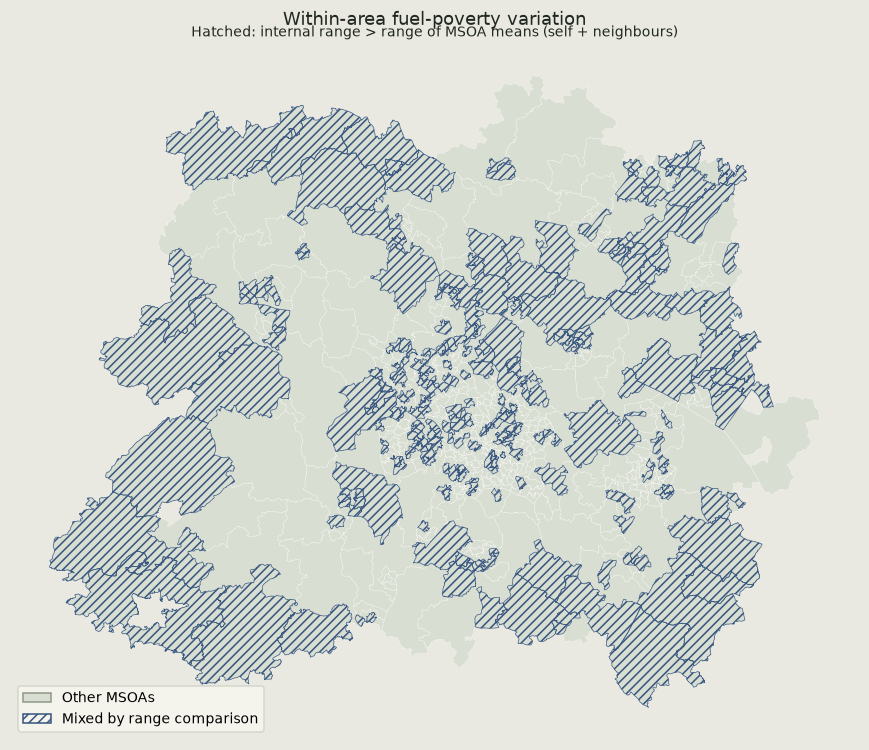

Mapped 660 MSOAs; 255 are hatched by the revised rule.


In [5]:
# Check that the saved boundaries cover exactly the same MSOAs as the summary.
boundary_path = raw_file("ons_msoa21_boundaries_exploratory_west_midlands.geojson")
boundaries = gpd.read_file(boundary_path)
boundary_code_field = next(field for field in boundaries.columns if field != "geometry"
    and boundaries[field].astype(str).str.fullmatch(r"[EW]020\d{5}").all())
assert boundaries[boundary_code_field].is_unique and len(boundaries) == EXPECTED_MSOAS
assert set(boundaries[boundary_code_field]) == set(area_summary["msoa_code"])
assert boundaries.crs is not None and boundaries.geometry.notna().all()
assert boundaries.geometry.is_valid.all()
# Project to British National Grid and attach the mixed flag using MSOA codes.
boundaries_by_code = boundaries.set_index(boundary_code_field).to_crs(27700)
assert boundaries_by_code.crs.to_epsg() == 27700
map_data = boundaries_by_code.join(
    area_summary.set_index("msoa_code")[["mixed"]], how="left", validate="one_to_one")
assert map_data["mixed"].notna().all()

# Draw all MSOAs first, then hatch those meeting the descriptive range rule.
fig, ax = plt.subplots(figsize=(8, 8), facecolor=PAPER)
ax.set_facecolor(PAPER)
map_data.plot(ax=ax, color="#d9ded2", edgecolor="#ffffff", linewidth=.18)
mixed_map = map_data.loc[map_data["mixed"]]
mixed_map.plot(ax=ax, facecolor="none", edgecolor=ACCENT, linewidth=.45, hatch="////")
ax.legend(handles=[
    Patch(facecolor="#d9ded2", edgecolor="#8f9887", label="Other MSOAs"),
    Patch(facecolor="none", edgecolor=ACCENT, hatch="////", label="Mixed by range comparison"),
], loc="lower left", frameon=True, facecolor="#f7f6ef", edgecolor=RULE, fontsize=9)
ax.set_title("Within-area fuel-poverty variation", color=INK, pad=12)
ax.text(.5, 1.005, "Hatched: internal range > range of MSOA means (self + neighbours)",
        transform=ax.transAxes, ha="center", va="bottom", color=INK, fontsize=9)
ax.set_axis_off()
fig.tight_layout()
save_figure(fig, "09_mixed_areas_map.png")
print(f"Mapped {len(map_data):,} MSOAs; {int(map_data['mixed'].sum()):,} are hatched by the revised rule.")


## Comparing the two range distributions

I plot all 660 internal LSOA ranges beside the 660 local ranges of MSOA means. They use the same percentage-point scale, so the distributions can be compared directly; each MSOA contributes one value to each distribution.


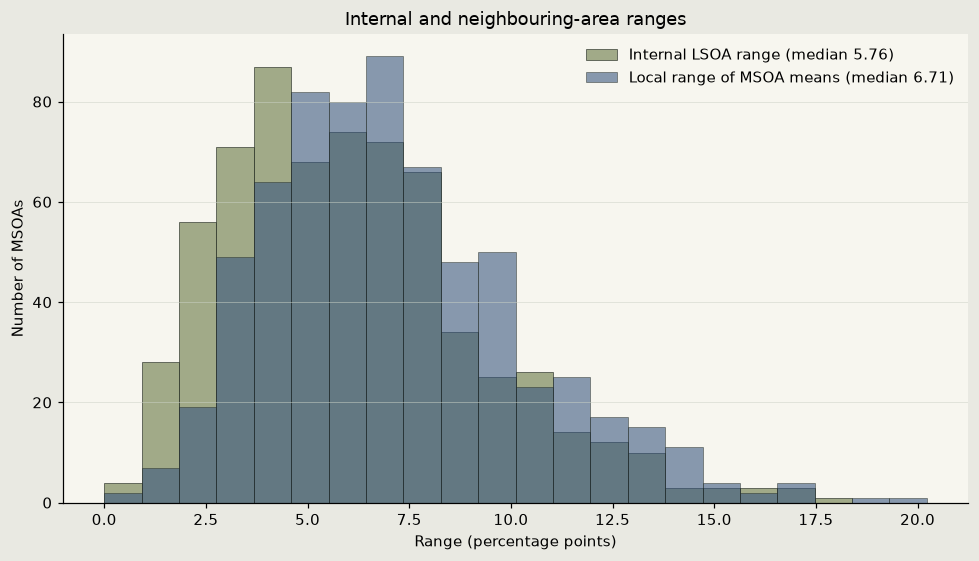

Histogram compares 660 internal ranges with 660 local ranges, on a shared scale.


In [6]:
# Compare the internal and local-context ranges on one percentage-point scale.
fig, ax = plt.subplots(figsize=(9, 5.2), facecolor=PAPER)
ax.set_facecolor("#f7f6ef")
range_values = np.concatenate([
    area_summary["fuel_poverty_range_percentage_points"].to_numpy(dtype=float),
    area_summary["neighbour_context_range_percentage_points"].to_numpy(dtype=float),
])
# Use shared histogram bins so the two distributions have directly comparable counts.
bins = np.linspace(0, range_values.max(), 23)
# Each MSOA contributes one internal range and one local-context range.
ax.hist(area_summary["fuel_poverty_range_percentage_points"], bins=bins,
        color=SAGE, edgecolor=INK, linewidth=.5, alpha=.78,
        label=f"Internal LSOA range (median {median_internal_range:.2f})")
ax.hist(area_summary["neighbour_context_range_percentage_points"], bins=bins,
        color=ACCENT, edgecolor=INK, linewidth=.5, alpha=.58,
        label=f"Local range of MSOA means (median {median_neighbour_context_range:.2f})")
ax.set(
    title="Internal and neighbouring-area ranges",
    xlabel="Range (percentage points)",
    ylabel="Number of MSOAs",
)
ax.grid(axis="y", color=RULE, alpha=.55, linewidth=.6)
ax.legend(frameon=False)
fig.tight_layout()
save_figure(fig, "09_internal_ranges_histogram.png")
print(f"Histogram compares {len(area_summary):,} internal ranges with {len(area_summary):,} local ranges, on a shared scale.")


## Saving the results

I save one row per MSOA, a JSON summary of the decomposition, comparison method and headline results, and a data dictionary. The saved table keeps full precision; rounding is only for display.


In [7]:
# Save one row per MSOA in a fixed code order, retaining full numerical precision.
area_summary = area_summary.sort_values("msoa_code", kind="mergesort").reset_index(drop=True)
csv_name = "msoa_fuel_poverty_aggregation.csv"
save_csv(area_summary, csv_name)

# Keep the earlier rule and its result recorded so the method change remains transparent.
method_change_note = (
    "The earlier mixed rule compared an internal range with a difference of means and was not like-for-like; "
    "it flagged 581/660 MSOAs (88.0%). It is replaced here by a range-versus-range comparison."
)
# Record variance components, the current range rule, sources and interpretation limits.
summary = {
    "msoa_count": int(len(area_summary)),
    "lsoa_count": int(lsoa["LSOA Code"].nunique()),
    "neighbour_pair_count": int(len(pairs)),
    "directed_neighbour_comparisons": int(2 * len(pairs)),
    "overall_lsoa_mean_pct": overall_lsoa_mean_pct,
    "total_lsoa_variance_percentage_points_squared": total_variance_percentage_points_squared,
    "within_msoa_variance_percentage_points_squared": within_variance_percentage_points_squared,
    "between_msoa_variance_percentage_points_squared": between_variance_percentage_points_squared,
    "within_msoa_variance_share_pct": within_variance_share_pct,
    "between_msoa_variance_share_pct": between_variance_share_pct,
    "variance_decomposition_reading": (
        f"About {within_variance_share_pct:.1f}% of variation among LSOA fuel-poverty percentages is within MSOAs; "
        "the remainder is between their LSOA-count-weighted means."
    ),
    "mixed_msoa_count": mixed_count,
    "mixed_msoa_share": mixed_share,
    "median_internal_range_percentage_points": median_internal_range,
    "median_neighbour_context_range_percentage_points": median_neighbour_context_range,
    "fuel_poverty_period": FUEL_POVERTY_PERIOD,
    "fuel_poverty_measure": "Household fuel-poverty proportion for each LSOA, expressed as a percentage.",
    "msoa_mean_method": "Unweighted mean of LSOA fuel-poverty proportions; each LSOA contributes once, regardless of household count.",
    "variance_decomposition_method": "Population variance across all LSOA percentages (ddof=0); within is the LSOA-count-weighted average of within-MSOA population variances, and between is the LSOA-count-weighted variance of MSOA means. LSOAs are equally weighted in the overall decomposition.",
    "standard_deviation_method": "Population standard deviation across the complete set of LSOA proportions inside each MSOA (ddof=0), in percentage points.",
    "coefficient_of_variation_method": "Population standard deviation divided by the unweighted mean of LSOA percentages; unitless ratio.",
    "neighbour_context_method": "For each MSOA, the local context contains its own unweighted mean and the means of all Notebook 04 neighbours; context range is maximum minus minimum in percentage points.",
    "mixed_rule": "True where the within-MSOA maximum-minus-minimum LSOA percentage range is strictly greater than the range of means across the focal MSOA and its Notebook 04 neighbours.",
    "method_change_note": method_change_note,
    "lsoa_to_msoa_source": "data/prepared/Geography/ons_lsoa21_to_msoa21_lad22_exploratory_west_midlands.csv",
    "neighbour_pair_source": "data/cleaned/Neighbours/neighbour_pairs.csv; area codes only, not HLE values.",
    "boundary_source": "ONS 2021 MSOA boundaries, saved exploratory West Midlands GeoJSON.",
    "output_folder": output_folder.relative_to(project_folder).as_posix(),
    "map_figure": "figures/09_mixed_areas_map.png",
    "histogram_figure": "figures/09_internal_ranges_histogram.png",
    "interpretation_limit": "Descriptive area-level comparison; not a test of statistical significance and not a statement about individual households or people.",
}
save_json(summary, "results_summary.json")

# Define every saved table column, including its unit and weighting method.
column_definitions = {
    "msoa_code": ("MSOA21 identifier", "Unique 2021 MSOA code."),
    "msoa_name": ("text", "2021 MSOA name from the ONS LSOA-to-MSOA lookup."),
    "lsoa_count": ("LSOAs", "Number of LSOAs contributing to the MSOA summary."),
    "fuel_poverty_mean_unweighted_pct": ("percent", "Unweighted mean of LSOA household fuel-poverty percentages; each LSOA has equal weight."),
    "fuel_poverty_min_pct": ("percent", "Minimum LSOA household fuel-poverty percentage in the MSOA."),
    "fuel_poverty_max_pct": ("percent", "Maximum LSOA household fuel-poverty percentage in the MSOA."),
    "fuel_poverty_range_percentage_points": ("percentage points", "Maximum minus minimum LSOA fuel-poverty percentage within the MSOA."),
    "fuel_poverty_sd_population_pct_points": ("percentage points", "Population standard deviation (ddof=0) of all contributing LSOA percentages within the MSOA."),
    "coefficient_of_variation": ("ratio", "Population standard deviation divided by the unweighted mean of LSOA percentages; unitless."),
    "neighbour_count": ("neighbouring MSOAs", "Number of Notebook 04 neighbour pairs touching this MSOA."),
    "neighbour_context_msoa_count": ("MSOAs", "Number of means in the local context: the focal MSOA plus its Notebook 04 neighbours."),
    "neighbour_context_mean_min_pct": ("percent", "Lowest unweighted LSOA fuel-poverty mean among the focal MSOA and its neighbours."),
    "neighbour_context_mean_max_pct": ("percent", "Highest unweighted LSOA fuel-poverty mean among the focal MSOA and its neighbours."),
    "neighbour_context_range_percentage_points": ("percentage points", "Maximum minus minimum of the MSOA means in the focal area plus its Notebook 04 neighbours."),
    "mixed": ("boolean", "True when the internal LSOA range is strictly greater than the local range of MSOA means across the focal MSOA and its neighbours."),
}
# Describe the summary keys separately from the per-MSOA table columns.
summary_definitions = {
    "msoa_count": ("MSOAs", "Number of MSOAs in the complete matched output."),
    "lsoa_count": ("LSOAs", "Number of unique LSOAs included."),
    "neighbour_pair_count": ("pairs", "Undirected neighbour pairs from Notebook 04."),
    "directed_neighbour_comparisons": ("comparisons", "One endpoint comparison per area endpoint for every undirected pair."),
    "overall_lsoa_mean_pct": ("percent", "Mean of all LSOA fuel-poverty percentages, with each LSOA equally weighted."),
    "total_lsoa_variance_percentage_points_squared": ("percentage-points squared", "Population variance of all included LSOA fuel-poverty percentages."),
    "within_msoa_variance_percentage_points_squared": ("percentage-points squared", "LSOA-count-weighted average of population variances within MSOAs."),
    "between_msoa_variance_percentage_points_squared": ("percentage-points squared", "LSOA-count-weighted variance of MSOA means around the overall LSOA mean."),
    "within_msoa_variance_share_pct": ("percent", "Within-MSOA component divided by total variance."),
    "between_msoa_variance_share_pct": ("percent", "Between-MSOA component divided by total variance."),
    "variance_decomposition_reading": ("text", "Plain-English reading of the within and between variance shares."),
    "mixed_msoa_count": ("MSOAs", "Areas whose internal LSOA range exceeds the local range of MSOA means."),
    "mixed_msoa_share": ("fraction 0–1", "Mixed MSOAs divided by all included MSOAs."),
    "median_internal_range_percentage_points": ("percentage points", "Median within-MSOA LSOA percentage range."),
    "median_neighbour_context_range_percentage_points": ("percentage points", "Median local range of MSOA means across each focal area and its neighbours."),
    "fuel_poverty_period": ("year", "Year of the fuel-poverty source data."),
    "fuel_poverty_measure": ("text", "Description of the source measure."),
    "msoa_mean_method": ("text", "Definition of the unweighted mean used for each MSOA."),
    "variance_decomposition_method": ("text", "Definition of the equal-LSOA total, within and between population variance components."),
    "standard_deviation_method": ("text", "Definition of within-MSOA population standard deviation."),
    "coefficient_of_variation_method": ("text", "Definition of coefficient of variation."),
    "neighbour_context_method": ("text", "Definition of the local comparison set and its range."),
    "mixed_rule": ("text", "Strict like-for-like range rule used to flag a mixed MSOA."),
    "method_change_note": ("text", "Why the earlier method was replaced and its prior result, retained for transparency."),
    "lsoa_to_msoa_source": ("project-relative path", "Saved lookup used to map LSOAs to MSOAs."),
    "neighbour_pair_source": ("project-relative path", "Saved Notebook 04 neighbour-pair file."),
    "boundary_source": ("text", "Geographic boundary source used in the map."),
    "output_folder": ("project-relative path", "Folder holding this analysis's saved outputs."),
    "map_figure": ("project-relative path", "Hatched map of mixed MSOAs."),
    "histogram_figure": ("project-relative path", "Comparison of internal and local-context ranges."),
    "interpretation_limit": ("text", "Scope limit for interpreting the descriptive comparison."),
}
# Build dictionary rows for the CSV columns, JSON keys and dictionary's own fields.
dictionary_rows = [
    {"file": csv_name, "column": column, "unit": unit, "meaning": meaning,
     "missing_rule": "No missing values"}
    for column, (unit, meaning) in column_definitions.items()
]
for key, value in summary.items():
    unit, meaning = summary_definitions[key]
    dictionary_rows.append({"file": "results_summary.json", "column": key, "unit": unit,
                            "meaning": meaning, "missing_rule": "Not applicable"})
for column, definition in {
    "file": ("text", "Saved output file described by this row."),
    "column": ("text", "CSV column or top-level JSON key."),
    "unit": ("text", "Measurement unit or field type."),
    "meaning": ("text", "What the field records."),
    "missing_rule": ("text", "How a blank or non-applicable value should be read."),
}.items():
    dictionary_rows.append({"file": "data_dictionary.csv", "column": column,
                            "unit": definition[0], "meaning": definition[1],
                            "missing_rule": "Not applicable"})
# Check complete, unique dictionary coverage before saving it.
data_dictionary = pd.DataFrame(dictionary_rows)
assert not data_dictionary.duplicated(["file", "column"]).any()
assert set(data_dictionary.query("file == @csv_name")["column"]) == set(area_summary.columns)
assert set(data_dictionary.query("file == 'results_summary.json'")["column"]) == set(summary)
save_csv(data_dictionary, "data_dictionary.csv")

print(f"Saved {len(area_summary):,} MSOA rows, {len(list(figure_folder.glob('*.png')))} figures, results_summary.json and data_dictionary.csv.")
print(f"Variance headline: within {within_variance_share_pct:.1f}% and between {between_variance_share_pct:.1f}% of total LSOA variance.")
print(f"Mixed by the like-for-like range rule: {mixed_count:,} of {len(area_summary):,} ({mixed_share:.1%}).")


Saved 660 MSOA rows, 2 figures, results_summary.json and data_dictionary.csv.
Variance headline: within 30.3% and between 69.7% of total LSOA variance.
Mixed by the like-for-like range rule: 255 of 660 (38.6%).


## What this means ethically

These summaries compare LSOA-level percentages and MSOA means, not households or people. The variance decomposition gives each LSOA equal weight, and the MSOA means used in the between-area component are weighted by each area's LSOA count. Neither is a household-weighted fuel-poverty rate. The mixed flag depends on the saved geography, Notebook 04's neighbour definition and a strict range-versus-range rule; it is descriptive, not a significance test. A hatched MSOA does not say every LSOA inside it has the same experience. I use the results to make the effects of aggregation visible, not to label communities or guide decisions about individuals.
